In [51]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import (
    AdaBoostClassifier, GradientBoostingClassifier, VotingClassifier
)
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [52]:
df = pd.read_csv("iris.csv")

In [53]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [54]:
X = df.drop(columns = ["Id", "Species"], errors="ignore")
encoder = LabelEncoder()
y = encoder.fit_transform(df["Species"])

In [55]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=47, stratify=y)

In [56]:
ada = AdaBoostClassifier(n_estimators = 50, random_state = 42 )
gbm = GradientBoostingClassifier(n_estimators = 100, random_state = 42)
xgb = XGBClassifier( n_estimators=100, max_depth=3, learning_rate=0.1, objective="multi:softprob", num_class=3, eval_metric="mlogloss", random_state=42)

In [57]:
hard = VotingClassifier(
    estimators = [("ada",ada),("gbm",gbm),("xgb",xgb)],
    voting="hard"
)

In [58]:
soft = VotingClassifier(
    estimators = [("ada",ada),("gbm",gbm),("xgb",xgb)],
    voting="soft"
)

In [59]:
models = {
    "AdaBoost": ada,
    "Gradient Boosting": gbm,
    "XGBoost": xgb,
    "Hard Voting": hard,
    "Soft Voting": soft
}

In [60]:
results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Error Rate": 1 - accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, pred, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, pred, average="weighted"
        )
    })

    print("\nModel:", name)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, pred))

    print("\nClassification Report:")
    print(classification_report(y_test, pred))


Model: AdaBoost
Confusion Matrix:
[[10  0  0]
 [ 0  8  2]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.80      0.89        10
           2       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


Model: Gradient Boosting
Confusion Matrix:
[[10  0  0]
 [ 0  8  2]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.80      0.89        10
           2       0.83      1.00      0.91        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30


Model: XGBoost
Confusion Matrix:
[[1

In [61]:
result_df = pd.DataFrame(results)
result_df

,Model,Accuracy,Error Rate,Precision,Recall,F1 Score
0,AdaBoost,0.933333,0.066667,0.944444,0.933333,0.93266
1,Gradient Boosting,0.933333,0.066667,0.944444,0.933333,0.93266
2,XGBoost,0.933333,0.066667,0.944444,0.933333,0.93266
3,Hard Voting,0.933333,0.066667,0.944444,0.933333,0.93266
4,Soft Voting,0.933333,0.066667,0.944444,0.933333,0.93266



Model: AdaBoost
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Model: Gradient Boosting
Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       1.00      0.90      0.95        10
           2       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30


Model: XGBoost
Confusion Matrix:
[[1

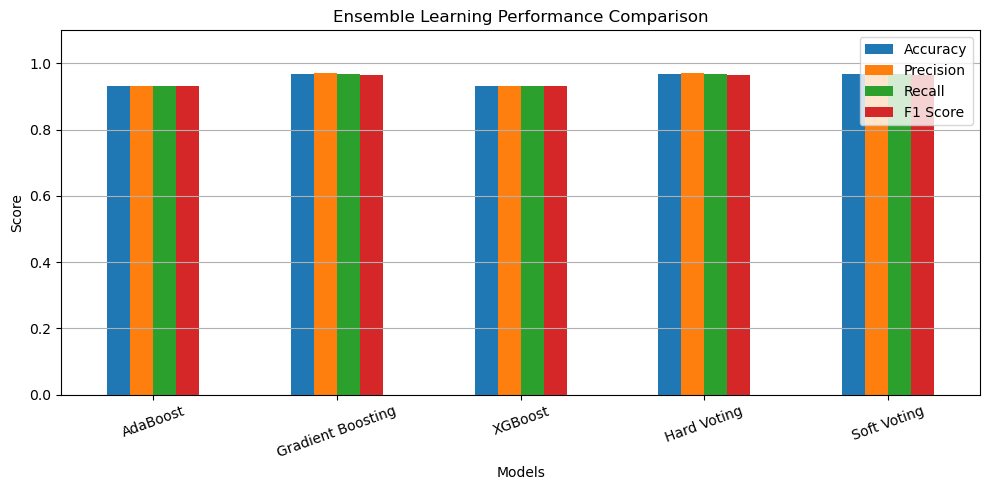


BEST MODEL: Gradient Boosting
BEST ACCURACY: 0.967


In [63]:

# Ensemble Learning on Iris Dataset

# Install XGBoost if required:
# %pip install xgboost

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)


# 1. Load dataset
df = pd.read_csv("Iris.csv")

X = df.drop(columns=["Id", "Species"], errors="ignore")
y = LabelEncoder().fit_transform(df["Species"])


# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# 3. Create boosting models
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=50,
    random_state=42
)

gbm = GradientBoostingClassifier(
    n_estimators=100,
    random_state=42
)

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=3,
    learning_rate=0.1,
    objective="multi:softprob",
    num_class=3,
    eval_metric="mlogloss",
    random_state=42
)


# 4. Create voting classifiers
hard = VotingClassifier(
    estimators=[
        ("ada", ada),
        ("gbm", gbm),
        ("xgb", xgb)
    ],
    voting="hard"
)

soft = VotingClassifier(
    estimators=[
        ("ada", ada),
        ("gbm", gbm),
        ("xgb", xgb)
    ],
    voting="soft"
)


# 5. Store all models
models = {
    "AdaBoost": ada,
    "Gradient Boosting": gbm,
    "XGBoost": xgb,
    "Hard Voting": hard,
    "Soft Voting": soft
}


# 6. Train and evaluate models
results = []

for name, model in models.items():

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Error Rate": 1 - accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, average="weighted"
        ),
        "Recall": recall_score(
            y_test, pred, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, pred, average="weighted"
        )
    })

    print("\nModel:", name)
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, pred))

    print("\nClassification Report:")
    print(classification_report(y_test, pred))


# 7. Display comparison table
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
print(results_df.round(3).to_string(index=False))


# 8. Plot comparison graph
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("Ensemble Learning Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Models")
plt.ylim(0, 1.1)
plt.xticks(rotation=20)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


# 9. Find best model
best = results_df.loc[results_df["Accuracy"].idxmax()]

print("\nBEST MODEL:", best["Model"])
print("BEST ACCURACY:", round(best["Accuracy"], 3))
